# Applications IV: Classical Mechanics and Chaos

- [A4.1 The nonlinear pendulum: beyond small angles](#pendulum) - *Gaussian quadrature, ODE events (Ch. 4, 5)*
- [A4.2 The damped, driven pendulum and the road to chaos](#driven) - *RK4 (Ch. 5)*
- [A4.3 Poincaré sections](#poincare) - *RK4 (Ch. 5)*
- [A4.4 A bifurcation diagram (vectorised RK4)](#bifurcation) - *RK4 + numpy vectorisation (Ch. 5)*
- [A4.5 The Lorenz attractor and the butterfly effect](#lorenz) - *`solve_ivp` (Ch. 5)*
- [A4.6 Measuring chaos: the Lyapunov exponent](#lyapunov) - *ODEs, curve fitting (Ch. 5, 9)*
- [Projects](#projects)

Newtonian mechanics is perfectly deterministic, yet in 1963 Edward Lorenz discovered - on a computer - that a deterministic system can be utterly unpredictable. Chaos is a field born from numerical methods.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.special import ellipk

def rk4_step(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + h/2, y + h/2*k1)
    k3 = f(t + h/2, y + h/2*k2)
    k4 = f(t + h, y + h*k3)
    return y + h/6*(k1 + 2*k2 + 2*k3 + k4)

# A4.1 The nonlinear pendulum: beyond small angles <a class="anchor" id="pendulum"></a>
Every first-year student learns $T_0 = 2\pi\sqrt{L/g}$, which relies on $\sin\theta\approx\theta$. The real equation is $\ddot\theta = -\frac{g}{L}\sin\theta$. Energy conservation gives the exact period as an integral,

$$T = 4\sqrt{\frac{L}{g}}\int_0^{\pi/2}\frac{d\phi}{\sqrt{1-k^2\sin^2\phi}} = 4\sqrt{\frac{L}{g}}\,K(k),\qquad k=\sin\frac{\theta_0}{2},$$

a **complete elliptic integral of the first kind**. We'll get $T(\theta_0)$ two independent ways:
1. **Gauss-Legendre quadrature** of the integral (Chapter 4).
2. **Direct simulation**, using an *event* to detect when $\dot\theta$ changes sign (a quarter period after release).

max |quadrature - exact| = 7.8e-04
max |simulation - exact| = 1.5e-10
small-angle formula is 1% wrong by theta0 ≈ 25 degrees


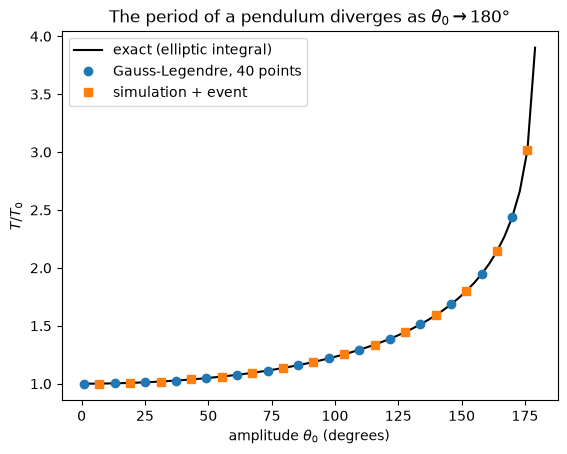

In [2]:
def period_quadrature(theta0, n=40):
    k = np.sin(theta0/2)
    t, w = np.polynomial.legendre.leggauss(n)
    phi = np.pi/4*(t + 1)                           # map [-1, 1] -> [0, pi/2]
    return 4*np.pi/4*np.sum(w/np.sqrt(1 - k**2*np.sin(phi)**2))     # in units of sqrt(L/g)

def period_simulation(theta0):
    rhs = lambda t, y: [y[1], -np.sin(y[0])]
    turn = lambda t, y: y[0]                        # theta = 0 is reached a quarter period after release
    turn.terminal, turn.direction = True, -1
    sol = solve_ivp(rhs, (0, 100), [theta0, 0], events=turn, rtol=1e-11, atol=1e-12)
    return 4*sol.t_events[0][0]

theta0 = np.radians(np.linspace(1, 179, 60))
T_quad = np.array([period_quadrature(th) for th in theta0])
T_sim = np.array([period_simulation(th) for th in theta0])
T_exact = 4*ellipk(np.sin(theta0/2)**2)             # scipy uses the parameter m = k^2

print(f'max |quadrature - exact| = {np.max(np.abs(T_quad - T_exact)):.1e}')
print(f'max |simulation - exact| = {np.max(np.abs(T_sim - T_exact)):.1e}')
first = np.degrees(theta0[np.argmax(T_exact/(2*np.pi) > 1.01)])
print(f'small-angle formula is 1% wrong by theta0 ≈ {first:.0f} degrees')

plt.plot(np.degrees(theta0), T_exact/(2*np.pi), 'k', label='exact (elliptic integral)')
plt.plot(np.degrees(theta0[::4]), T_quad[::4]/(2*np.pi), 'o', label='Gauss-Legendre, 40 points')
plt.plot(np.degrees(theta0[2::4]), T_sim[2::4]/(2*np.pi), 's', label='simulation + event')
plt.xlabel(r'amplitude $\theta_0$ (degrees)'); plt.ylabel('$T/T_0$'); plt.legend()
plt.title('The period of a pendulum diverges as $\\theta_0 \\to 180°$'); plt.show()

Notice that Gauss-Legendre struggles near $180^\circ$, where the integrand develops a near-singularity at $\phi=\pi/2$ - quadrature methods love smooth integrands.

# A4.2 The damped, driven pendulum and the road to chaos <a class="anchor" id="driven"></a>
Add damping and a periodic driving torque:

$$\ddot\theta + \frac{1}{q}\dot\theta + \sin\theta = F\cos(\Omega t).$$

This simple-looking equation (also the equation of a Josephson junction in a superconducting circuit!) has an extraordinarily rich behaviour as the drive strength $F$ increases. We use the classic parameters $q=2$, $\Omega=2/3$ (from Baker & Gollub, *Chaotic Dynamics*).

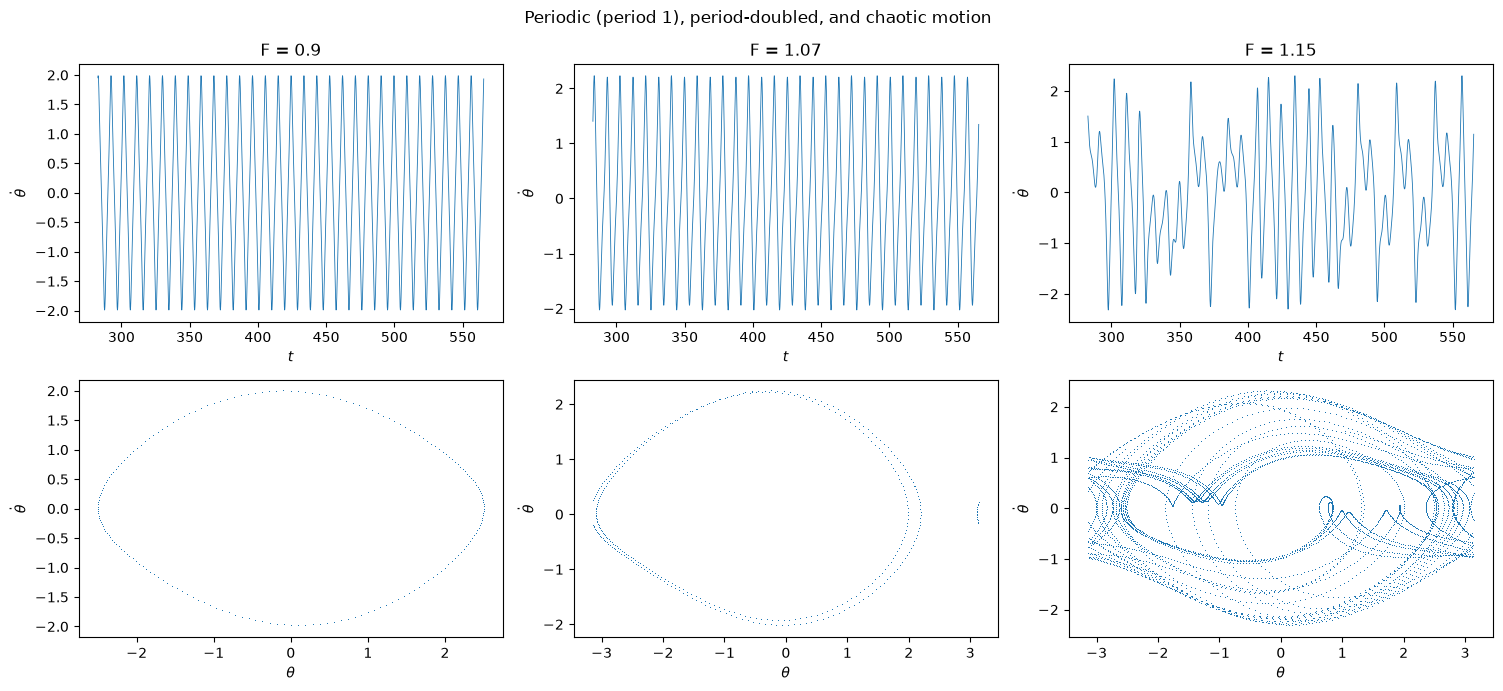

In [3]:
q, Omega = 2.0, 2/3

def driven(t, y, F):
    theta, omega = y
    return np.array([omega, -omega/q - np.sin(theta) + F*np.cos(Omega*t)])

T_drive = 2*np.pi/Omega
steps_per_period = 200
h = T_drive/steps_per_period

def simulate(F, n_periods, y0=(0.2, 0.0)):
    y = np.array(y0, float)
    out = np.zeros((n_periods*steps_per_period + 1, 2)); out[0] = y
    t = 0.0
    for n in range(n_periods*steps_per_period):
        y = rk4_step(lambda t, y: driven(t, y, F), t, y, h)
        t += h
        out[n+1] = y
    return np.arange(len(out))*h, out

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for col, F in enumerate([0.9, 1.07, 1.15]):
    t, y = simulate(F, 60)
    keep = t > 30*T_drive                                      # discard the transient
    wrapped = (y[:, 0] + np.pi) % (2*np.pi) - np.pi            # map theta into [-pi, pi)
    axes[0, col].plot(t[keep], y[keep, 1], lw=0.6); axes[0, col].set_title(f'F = {F}')
    axes[0, col].set_xlabel('$t$'); axes[0, col].set_ylabel(r'$\dot\theta$')
    axes[1, col].plot(wrapped[keep], y[keep, 1], ',', ms=1)
    axes[1, col].set_xlabel(r'$\theta$'); axes[1, col].set_ylabel(r'$\dot\theta$')
plt.suptitle('Periodic (period 1), period-doubled, and chaotic motion'); plt.tight_layout(); plt.show()

# A4.3 Poincaré sections <a class="anchor" id="poincare"></a>
The phase-space trajectory of a chaotic system is a tangled mess. Poincaré's trick: only look at the system **stroboscopically**, once per driving period. A period-1 orbit becomes a single dot, a period-2 orbit two dots, and a chaotic orbit traces out a **strange attractor** - a fractal set of points.

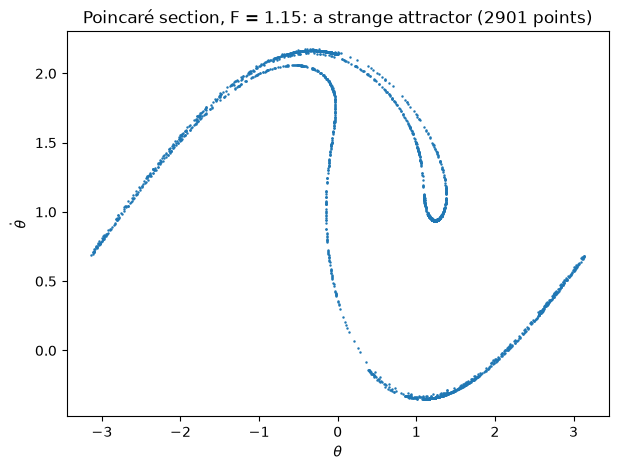

In [4]:
F = 1.15
t, y = simulate(F, 3000, y0=(0.2, 0.0))
strobe = y[::steps_per_period][100:]                           # one point per drive period
wrapped = (strobe[:, 0] + np.pi) % (2*np.pi) - np.pi

plt.figure(figsize=(7, 5))
plt.plot(wrapped, strobe[:, 1], '.', ms=1.5)
plt.xlabel(r'$\theta$'); plt.ylabel(r'$\dot\theta$')
plt.title(f'Poincaré section, F = {F}: a strange attractor ({len(strobe)} points)'); plt.show()

# A4.4 A bifurcation diagram (vectorised RK4) <a class="anchor" id="bifurcation"></a>
To see the whole road to chaos at once, scan $F$ and, for each value, plot the Poincaré-section values of $\dot\theta$ after the transient has died away. Period doubling appears as branches splitting in two, then four, then... chaos.

This needs hundreds of simulations. Rather than loop over $F$, we can integrate **all of them at once**: make $y$ an array of shape `(2, n_F)` and $F$ an array of length `n_F`. Our RK4 step is pure numpy arithmetic, so it works unchanged on arrays - one of the great payoffs of writing vectorised code.

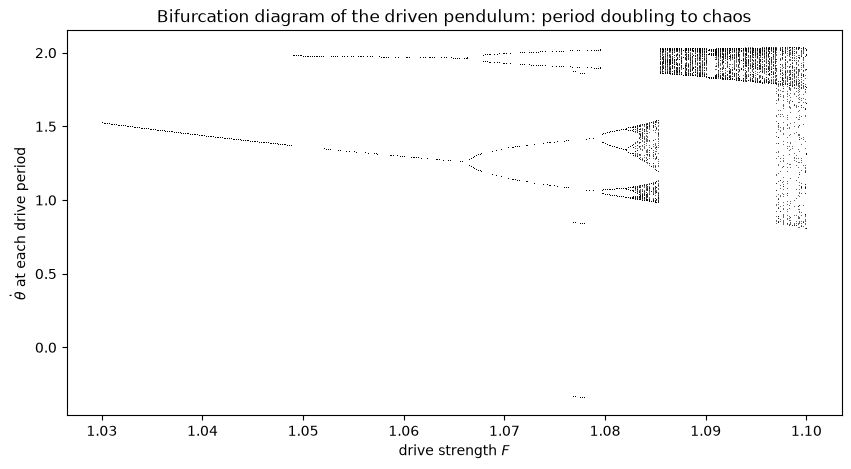

In [5]:
F_values = np.linspace(1.03, 1.10, 400)
y = np.vstack([np.full_like(F_values, -0.5), np.zeros_like(F_values)])     # shape (2, n_F)
f_vec = lambda t, y: np.array([y[1], -y[1]/q - np.sin(y[0]) + F_values*np.cos(Omega*t)])

t, n_transient, n_record = 0.0, 300, 60
points = []
for period in range(n_transient + n_record):
    for _ in range(steps_per_period):
        y = rk4_step(f_vec, t, y, h)
        t += h
    if period >= n_transient:
        points.append(y[1].copy())
points = np.array(points)

plt.figure(figsize=(10, 5))
plt.plot(np.tile(F_values, n_record), points.ravel(), ',k', alpha=0.6)
plt.xlabel('drive strength $F$'); plt.ylabel(r'$\dot\theta$ at each drive period')
plt.title('Bifurcation diagram of the driven pendulum: period doubling to chaos'); plt.show()

Follow the lower branch from the left: one line splits into two near $F\approx1.066$, then into four near $F\approx1.079$, and dissolves into a chaotic band soon after. You may notice a second set of branches near $\dot\theta\approx2$: for some values of $F$ the pendulum has **coexisting attractors** (e.g. a whirling, over-the-top motion as well as a swinging one), and which one it settles into depends on the starting point. Every $F$ here starts from the same initial condition, so the diagram jumps between them. Nonlinear systems are full of such surprises - always explore several initial conditions!

The ratio of successive period-doubling intervals converges to the **Feigenbaum constant** $\delta\approx4.669$ - a universal number shared by dripping taps, convection rolls, heart cells and the logistic map.

# A4.5 The Lorenz attractor and the butterfly effect <a class="anchor" id="lorenz"></a>
Lorenz's simplified model of atmospheric convection:

$$\dot x = \sigma(y - x),\qquad \dot y = x(\rho - z) - y,\qquad \dot z = xy - \beta z,$$

with the classic $\sigma=10$, $\rho=28$, $\beta=8/3$. Lorenz found that restarting a run from rounded-off numbers printed by his computer gave a completely different weather forecast after a while: **sensitive dependence on initial conditions**, popularly the *butterfly effect*.

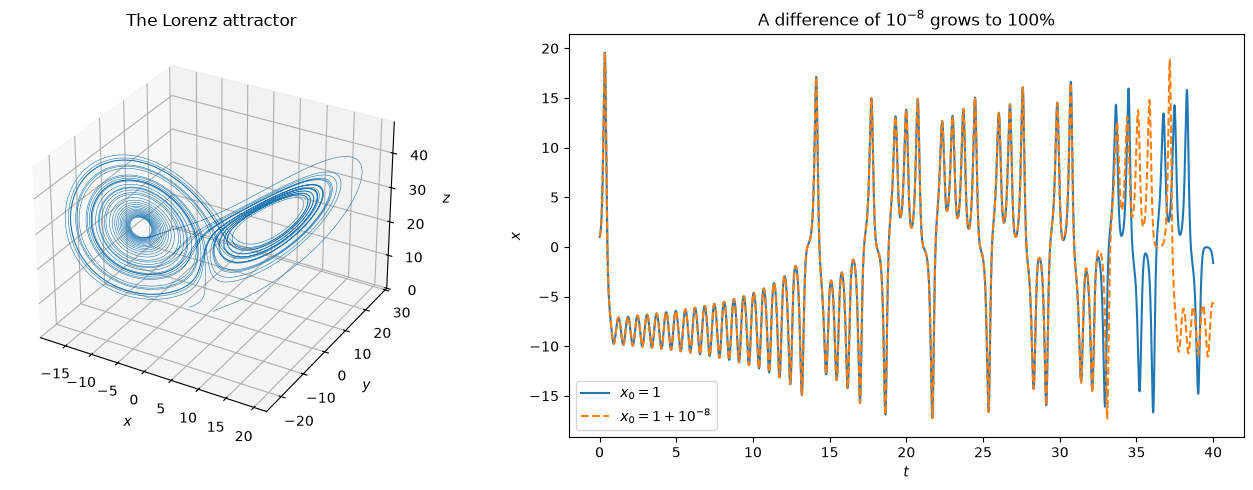

In [6]:
sigma, rho, beta = 10.0, 28.0, 8/3
lorenz = lambda t, s: [sigma*(s[1] - s[0]), s[0]*(rho - s[2]) - s[1], s[0]*s[1] - beta*s[2]]

t_eval = np.linspace(0, 40, 8000)
s1 = solve_ivp(lorenz, (0, 40), [1, 1, 1], t_eval=t_eval, rtol=1e-10, atol=1e-12)
s2 = solve_ivp(lorenz, (0, 40), [1 + 1e-8, 1, 1], t_eval=t_eval, rtol=1e-10, atol=1e-12)

fig = plt.figure(figsize=(14, 5))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.plot(*s1.y, lw=0.4)
ax.set_title('The Lorenz attractor'); ax.set_xlabel('$x$'); ax.set_ylabel('$y$'); ax.set_zlabel('$z$')
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(t_eval, s1.y[0], label='$x_0 = 1$')
ax2.plot(t_eval, s2.y[0], '--', label='$x_0 = 1 + 10^{-8}$')
ax2.set_xlabel('$t$'); ax2.set_ylabel('$x$'); ax2.legend(); ax2.set_title('A difference of $10^{-8}$ grows to 100%')
plt.tight_layout(); plt.show()

# A4.6 Measuring chaos: the Lyapunov exponent <a class="anchor" id="lyapunov"></a>
In a chaotic system, a tiny separation $\delta_0$ between two trajectories grows exponentially on average, $\delta(t)\approx\delta_0e^{\lambda t}$. The **largest Lyapunov exponent** $\lambda$ quantifies chaos: $\lambda>0$ means chaotic, and $1/\lambda$ is the *predictability horizon* (for the real atmosphere, about two weeks - which is why weather forecasts beyond that are useless).

The separation can't grow forever (the attractor is bounded), so the standard algorithm (Benettin et al., 1980) **renormalises**: evolve both trajectories for a short time $\tau$, record $\ln(\delta/\delta_0)$, rescale the separation back to $\delta_0$ along the same direction, and repeat. $\lambda$ is the average growth rate.

largest Lyapunov exponent of the Lorenz system: 0.896 (literature value 0.906)
predictability horizon for a 1e-8 initial error to reach O(1): ~21 time units


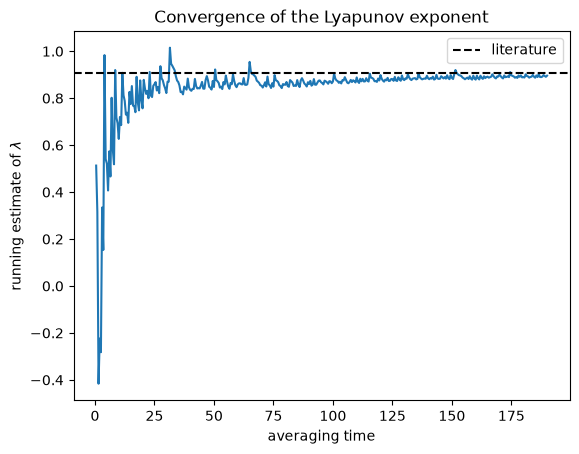

In [7]:
def lyapunov(f, s0, d0=1e-8, tau=0.5, n=400):
    a = np.array(s0, float)
    b = a + np.array([d0, 0, 0])
    logs = []
    for _ in range(n):
        a = solve_ivp(f, (0, tau), a, rtol=1e-10, atol=1e-12).y[:, -1]
        b = solve_ivp(f, (0, tau), b, rtol=1e-10, atol=1e-12).y[:, -1]
        d = np.linalg.norm(b - a)
        logs.append(np.log(d/d0))
        b = a + (b - a)*d0/d                     # renormalise
    logs = np.array(logs[20:])                   # skip the transient onto the attractor
    return np.cumsum(logs)/(tau*np.arange(1, len(logs) + 1))

running = lyapunov(lorenz, [1, 1, 1])
print(f'largest Lyapunov exponent of the Lorenz system: {running[-1]:.3f} (literature value 0.906)')
print(f'predictability horizon for a 1e-8 initial error to reach O(1): ~{np.log(1e8)/running[-1]:.0f} time units')

plt.plot(np.arange(1, len(running) + 1)*0.5, running)
plt.axhline(0.906, color='k', ls='--', label='literature')
plt.xlabel('averaging time'); plt.ylabel(r'running estimate of $\lambda$'); plt.legend()
plt.title('Convergence of the Lyapunov exponent'); plt.show()

# Projects <a class="anchor" id="projects"></a>

1. **The double pendulum.** Derive (or look up) the equations of motion for a double pendulum and simulate it. Make a map of "time until the lower pendulum first flips over" as a function of the two initial angles - a famous fractal picture.
2. **Feigenbaum's constant.** Zoom into the bifurcation diagram of A4.4 to locate the first three period-doubling points $F_1, F_2, F_3$ precisely (e.g. by bisection on the number of distinct Poincaré points) and estimate $\delta = (F_2 - F_1)/(F_3 - F_2)$.
3. **The logistic map.** The discrete map $x_{n+1} = rx_n(1-x_n)$ shows the same route to chaos. Plot its bifurcation diagram for $2.5<r<4$ (it's very fast!) and compute its Lyapunov exponent $\lambda = \lim\frac1N\sum\ln|r(1-2x_n)|$ as a function of $r$.
4. **Kepler orbits in a non-$1/r^2$ force.** Bertrand's theorem says only $1/r$ and $r^2$ potentials give closed orbits. Simulate a planet in a potential $\propto -1/r^{1.1}$ and watch the orbit precess into a rosette.
5. **The Hénon-Heiles system.** A model of a star moving in a galaxy, $V=\frac12(x^2+y^2)+x^2y-\frac13y^3$. Make Poincaré sections for energies $E=1/12, 1/8, 1/6$ and watch regular orbits (smooth curves) give way to chaos (scattered dots).

In [8]:
# Start working here

In [9]:
print("Lorenz's 1972 talk: 'Does the flap of a butterfly's wings in Brazil set off a tornado in Texas?' Rerun A4.5 to find out.")  # easter egg (deliberate)

Lorenz's 1972 talk: 'Does the flap of a butterfly's wings in Brazil set off a tornado in Texas?' Rerun A4.5 to find out.
